In [11]:
import jax
import jax.numpy as jnp
import jax.random as jrng
import jax.tree as jtu
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
@jax.jit
def compute_pc_error(vs, Ws, x, rclamp):
    if rclamp is None:
        rs = [jax.nn.tanh(v) for v in vs]
    else:
        rs = [*(jax.nn.tanh(v) for v in vs[:-1]), rclamp]
    vs_ff = [W @ r for W, r in zip(Ws, (x, *rs[:-1]))]
    es = jnp.array([jnp.sum((v - v_ff) ** 2) for v, v_ff in zip(vs, vs_ff)])
    E = 0.5 * jnp.sum(es)

    return E, (rs, vs_ff)

def pc_fwd_step(Ws, vs, x, rclamp = None, tau = 1, dt = 0.001):
    dEdvs, _ = jax.grad(compute_pc_error, has_aux=True)(vs, Ws, x, rclamp)
    if rclamp is None:
        vs_next = [v - dt * dEdv / tau for v, dEdv in zip(vs, dEdvs)]
    else:
        vs_next = [v - dt * dEdv / tau for v, dEdv in zip(vs[:-1], dEdvs[:-1])]
        vs_next = [*vs_next, vs[-1]]

    return vs_next

x = jrng.normal(jrng.PRNGKey(0), 10)
vs = [jrng.normal(jrng.PRNGKey(1), 8),
      jrng.normal(jrng.PRNGKey(2), 4),
      jrng.normal(jrng.PRNGKey(3), 2)]
Ws = [jrng.normal(jrng.PRNGKey(4 + i), (len(y), len(x)))
      for i, (x, y) in enumerate(zip((x, *vs[:-1]), vs))]

In [53]:
vs_t = [list(map(np.array, vs))]
vs_current = vs
for t in range(5000):
    _vs = pc_fwd_step(Ws, vs_current, x, tau=0.1)
    vs_t.append(list(map(np.array, _vs)))
    vs_current = _vs

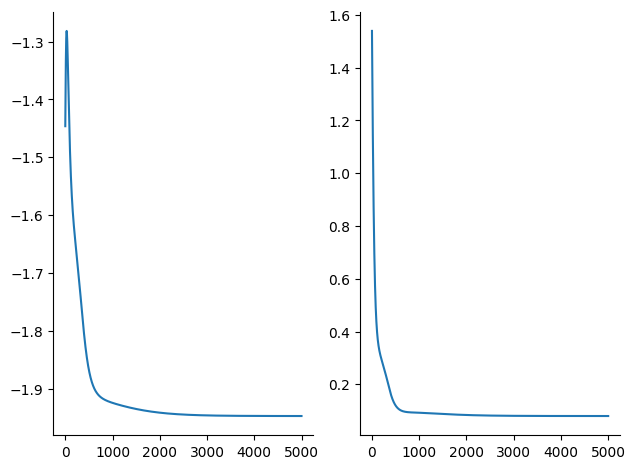

In [54]:
fig, axs = plt.subplots(ncols=2)

for i, ax in enumerate(axs):
    y = [v[2][i] for v in vs_t]
    sns.lineplot(x=np.arange(len(y)), y=y, ax=ax)
sns.despine(fig)
fig.tight_layout()

In [57]:
rclamp_delta = vs_t[-1][-1] + 0.001 * vs_t[-1][-1]

vs_t_delta = [list(map(np.array, vs))]
vs_current = vs
for t in range(5000):
    _vs = pc_fwd_step(Ws, vs_current, x, rclamp_delta, tau=0.1)
    vs_t_delta.append(list(map(np.array, _vs)))
    vs_current = _vs

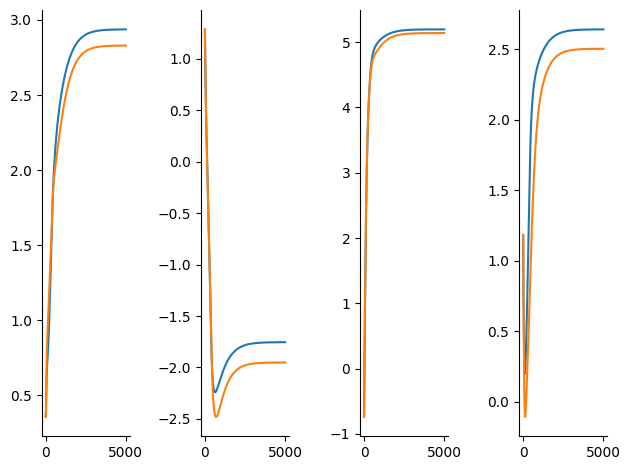

In [58]:
fig, axs = plt.subplots(ncols=4)

for i, ax in enumerate(axs):
    y = [v[1][i] for v in vs_t]
    sns.lineplot(x=np.arange(len(y)), y=y, ax=ax)
    y = [v[1][i] for v in vs_t_delta]
    sns.lineplot(x=np.arange(len(y)), y=y, ax=ax)
sns.despine(fig)
fig.tight_layout()

In [ ]:
jvps = [jax.jacobian(lambda v: W @ jax.nn.tanh(v)) for W in Ws]

def pc_approx_fwd_step(Ws, vs, x, rclamp = None, tau = 1, dt = 0.001):
    dEdvs, _ = jax.grad(compute_pc_error, has_aux=True)(vs, Ws, x, rclamp)
    if rclamp is None:
        vs_next = [v - dt * dEdv / tau for v, dEdv in zip(vs, dEdvs)]
    else:
        vs_next = [v - dt * dEdv / tau for v, dEdv in zip(vs[:-1], dEdvs[:-1])]
        vs_next = [*vs_next, vs[-1]]

    return vs_next